# Simulação

Compare um FIR Hamming de 51 coeficientes com um Butterworth IIR de ordem 4, ambos passa-baixas com parâmetro de corte de 100 Hz e fs = 1000 Hz.

Execute as células em ordem. Os dados são sintéticos; não representam medições experimentais.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from IPython.display import display
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

def espectro(x, fs, janela=None, nfft=None):
    w = np.ones(len(x)) if janela is None else janela
    X = np.fft.rfft(x*w, n=nfft)
    f = np.fft.rfftfreq(len(x) if nfft is None else nfft, 1/fs)
    A = np.abs(X)/w.sum()
    A[1:] *= 2
    if (len(x) if nfft is None else nfft) % 2 == 0:
        A[-1] /= 2
    return f, A

def plano(b, a, ax):
    # Coeficientes em potências de z^-1; completar graus para exibir polos na origem.
    grau = max(len(b), len(a))-1
    z = np.roots(np.pad(b, (0, grau+1-len(b))))
    p = np.roots(np.pad(a, (0, grau+1-len(a))))
    theta = np.linspace(0, 2*np.pi, 500)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo unitário')
    ax.scatter(z.real, z.imag, facecolors='none', edgecolors='C0', label='Zeros')
    ax.scatter(p.real, p.imag, marker='x', color='C1', label='Polos')
    ax.set(xlabel='Parte real', ylabel='Parte imaginária', title='Plano z')
    ax.axis('equal'); ax.legend()

def analisar(b, a=(1,), fs=1000, nome='Filtro'):
    w, H = signal.freqz(b, a, worN=4096, fs=fs)
    impulso = np.r_[1., np.zeros(119)]
    h = signal.lfilter(b, a, impulso)
    fig, ax = plt.subplots(2, 3, figsize=(14, 7))
    ax[0,0].stem(np.arange(len(h)), h); ax[0,0].set(title=nome+' — impulso', xlabel='n (amostras)', ylabel='h[n]')
    plano(np.asarray(b), np.asarray(a), ax[0,1])
    ax[0,2].plot(w, np.abs(H)); ax[0,2].set(title='Magnitude linear', xlabel='f (Hz)', ylabel='Ganho')
    ax[1,0].plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12))); ax[1,0].set(title='Magnitude em dB', xlabel='f (Hz)', ylabel='Ganho (dB)', ylim=(-100,5))
    fase = np.unwrap(np.angle(H))
    ax[1,1].plot(w, fase); ax[1,1].set(title='Fase', xlabel='f (Hz)', ylabel='Fase (rad)')
    gd = -np.gradient(fase, 2*np.pi*w/fs)
    gd[np.abs(H)<1e-5] = np.nan
    ax[1,2].plot(w, gd); ax[1,2].set(title='Atraso de grupo (fora dos nulos)', xlabel='f (Hz)', ylabel='Amostras')
    fig.tight_layout(); plt.show()
    print('b =', np.asarray(b)); print('a =', np.asarray(a))
    print('Polos:', np.roots(a), 'Estável causal:', np.all(np.abs(np.roots(a)) < 1))


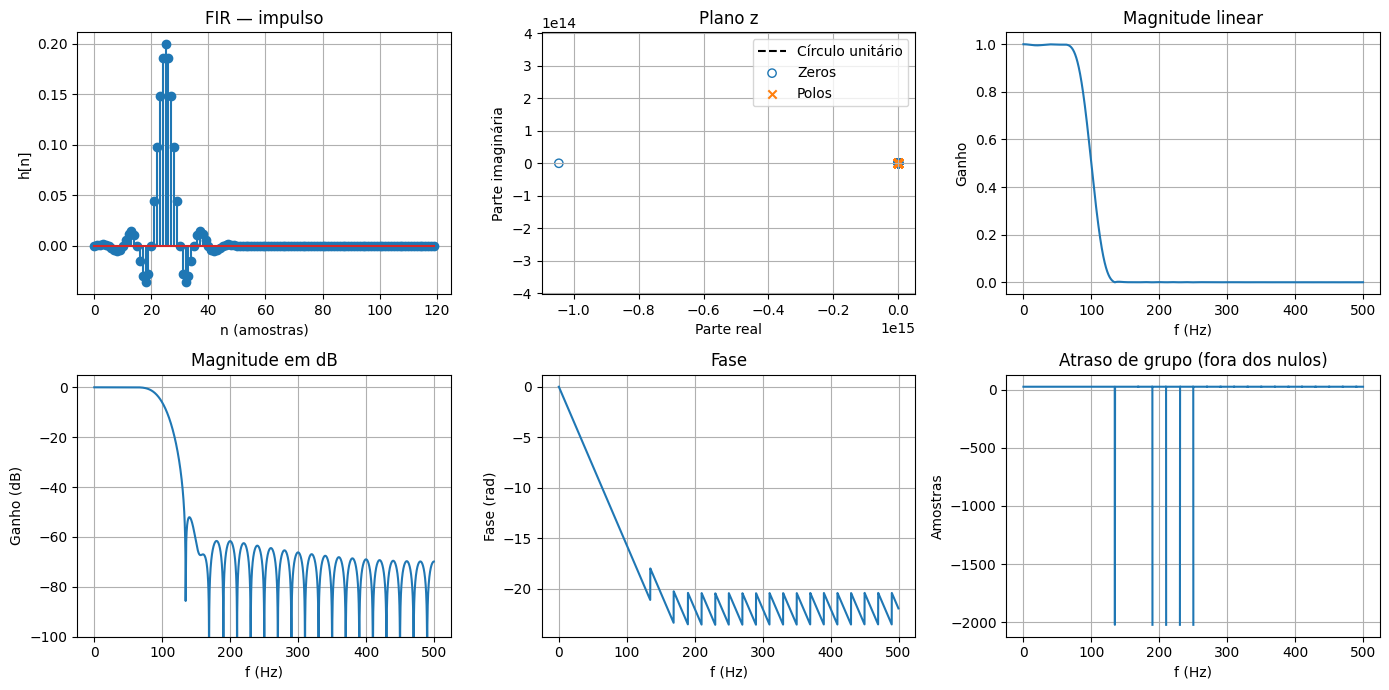

b = [ 6.22233219e-19  6.50395537e-04  1.24025458e-03  1.54168857e-03
  1.21680726e-03 -1.30554005e-18 -2.01071740e-03 -4.14071058e-03
 -5.21455172e-03 -4.01474662e-03  3.09446055e-18  6.05036949e-03
  1.18742206e-02  1.43176216e-02  1.06257168e-02 -5.30568790e-18
 -1.52613457e-02 -2.96911186e-02 -3.59490768e-02 -2.72307378e-02
  7.09460841e-18  4.40087761e-02  9.74197266e-02  1.48825236e-01
  1.85978564e-01  1.99527255e-01  1.85978564e-01  1.48825236e-01
  9.74197266e-02  4.40087761e-02  7.09460841e-18 -2.72307378e-02
 -3.59490768e-02 -2.96911186e-02 -1.52613457e-02 -5.30568790e-18
  1.06257168e-02  1.43176216e-02  1.18742206e-02  6.05036949e-03
  3.09446055e-18 -4.01474662e-03 -5.21455172e-03 -4.14071058e-03
 -2.01071740e-03 -1.30554005e-18  1.21680726e-03  1.54168857e-03
  1.24025458e-03  6.50395537e-04  6.22233219e-19]
a = [1]
Polos: [] Estável causal: True
FIR ordem = 50 coeficientes armazenados = 51 multiplicações/amostra (forma direta) = 51


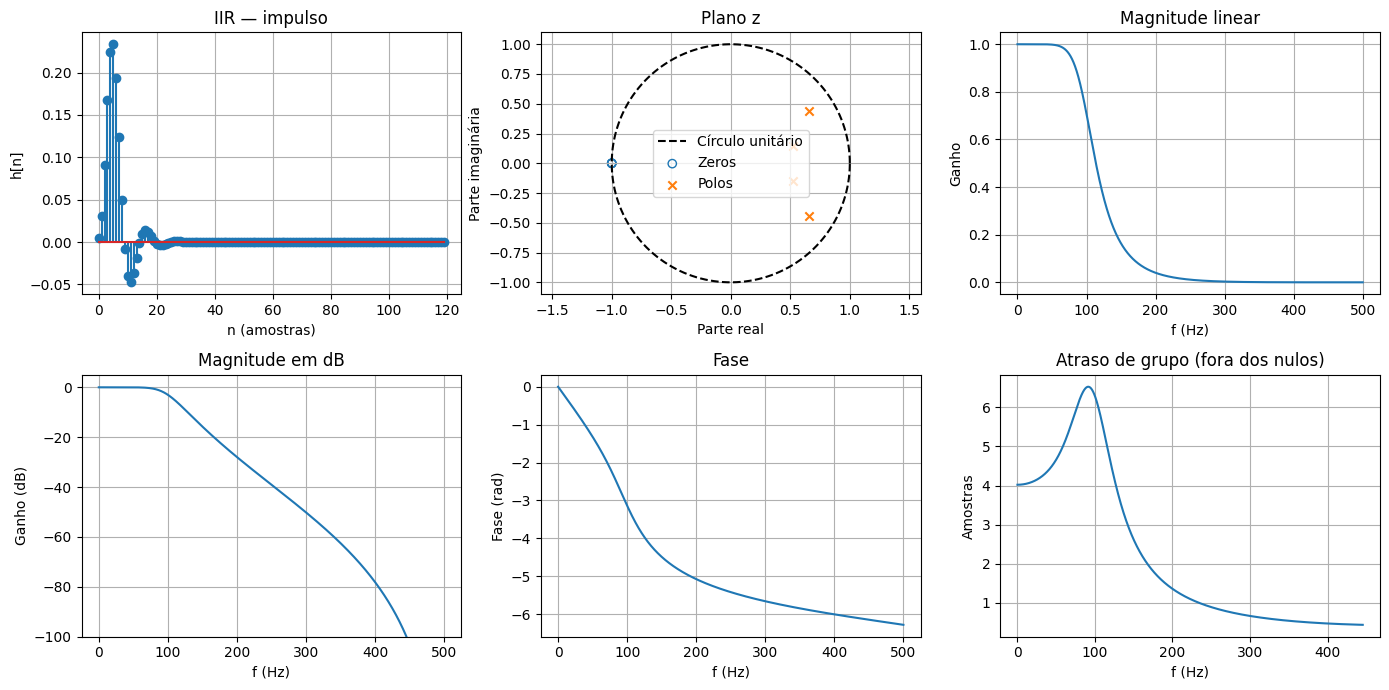

b = [0.00482434 0.01929737 0.02894606 0.01929737 0.00482434]
a = [ 1.         -2.36951301  2.31398841 -1.05466541  0.18737949]
Polos: [0.66045672+0.44332349j 0.66045672-0.44332349j 0.52429979+0.1457741j
 0.52429979-0.1457741j ] Estável causal: True
IIR ordem = 4 coeficientes armazenados = 9 multiplicações/amostra (forma direta) = 9


In [2]:
fs=1000; bfir=signal.firwin(51,100,fs=fs); biir,aiir=signal.butter(4,100,fs=fs)
for nome,b,a in [('FIR',bfir,[1]),('IIR',biir,aiir)]:
    analisar(b,a,fs,nome)
    print(nome,'ordem =',max(len(b),len(a))-1,'coeficientes armazenados =',len(b)+len(a)-1,'multiplicações/amostra (forma direta) =',len(b)+len(a)-1)
